In [1]:
import pandas as pd
import geopandas as gpd

base = '/Users/christiantodorov/Downloads/boston_311/'

df = pd.read_csv(base + '311 2023 data.csv', low_memory=False)
income = pd.read_csv(base + 'ACSDT5Y2024/ACSDT5Y2024.B19013-Data.csv', skiprows=[1])
tracts = gpd.read_file(base + 'tl_2024_25_tract/')

print(df.shape, income.shape, tracts.shape)


(307791, 30) (235, 5) (1620, 14)


In [2]:
print(df.columns.tolist())
df['type'].value_counts().head(30)

['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt', 'on_time', 'case_status', 'closure_reason', 'case_title', 'subject', 'reason', 'type', 'queue', 'department', 'submitted_photo', 'closed_photo', 'location', 'fire_district', 'pwd_district', 'city_council_district', 'police_district', 'neighborhood', 'neighborhood_services_district', 'ward', 'precinct', 'location_street_name', 'location_zipcode', 'latitude', 'longitude', 'geom_4326', 'source']


type
Parking Enforcement                            56813
Mattress_Pickup                                28013
Requests for Street Cleaning                   21817
Improper Storage of Trash (Barrels)            19460
CE Collection                                  15420
Schedule a Bulk Item Pickup                    13287
Missed Trash/Recycling/Yard Waste/Bulk Item    12588
Request for Pothole Repair                     11828
Poor Conditions of Property                     8225
Needle Pickup                                   7413
Tree Maintenance Requests                       6996
Pick up Dead Animal                             6892
Sign Repair                                     5908
Sidewalk Repair (Make Safe)                     5617
Schedule a Bulk Item Pickup SS                  5346
Street Light Outages                            4893
Abandoned Vehicles                              4595
Request for Recycling Cart                      4197
Ground Maintenance                       

In [3]:
types = ['Request for Pothole Repair', 'Street Light Outages', 'Sidewalk Repair (Make Safe)']
d = df[df['type'].isin(types)].copy()

d['open_dt'] = pd.to_datetime(d['open_dt'], format='mixed', errors='coerce', utc=True)
d['closed_dt'] = pd.to_datetime(d['closed_dt'], format='mixed', errors='coerce', utc=True)

print(d['open_dt'].isna().sum(), d['closed_dt'].isna().sum())

d = d[d['case_status'] == 'Closed']
d['response_days'] = (d['closed_dt'] - d['open_dt']).dt.total_seconds() / 86400

print(d.shape)
d.groupby('type')['response_days'].describe()

0 6026
(16312, 31)


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Request for Pothole Repair,8374.0,13.980644,75.907194,0.000090,0.156480,1.554789,5.101783,1086.792943
Sidewalk Repair (Make Safe),3393.0,86.842856,190.399482,0.000214,0.684029,2.725327,64.934932,1113.789650
Street Light Outages,4545.0,54.372928,111.370761,0.000039,0.061264,2.339069,51.148158,976.489615


In [4]:
d['closure_reason'].str[:80].value_counts().head(25)


closure_reason
Case Closed Case Noted  Dear Constituent  The Public Works Construction Inspecti    100
Case Closed Case Noted  Contractor & Utility notified                                87
Case Closed Case Invalid                                                             70
Case Closed Case Noted  The Utility/contractor has been notified                     51
Case Closed Case Noted  The Contractors & Utilities have been notified. If this      50
Case Closed Case Noted                                                               46
Case Closed Case Noted  BWSC has been notified                                       42
Case Closed Case Noted  The Utility has been notified                                39
Case Closed Case Noted  Contractor has been notified                                 37
Case Closed Case Noted  The Utilities & Contractors have been notified               37
Case Closed Case Noted  This has been addressed                                      37
Case Closed Case 

In [5]:
d['closure_type'] = d['closure_reason'].str.extract(r'Case Closed\.?\s*Case (\w+)')[0]

print(d['closure_type'].value_counts(dropna=False))
d.groupby(['type', 'closure_type'])['response_days'].agg(['count', 'median']).round(2)

closure_type
NaN         14808
Noted        1285
Resolved      138
Invalid        72
Referred        9
Name: count, dtype: int64


count  median
type                        closure_type               
Request for Pothole Repair  Invalid          39    0.19
                            Noted          1255    9.91
                            Referred          9    1.80
                            Resolved        127    8.75
Sidewalk Repair (Make Safe) Invalid          33    0.44
                            Noted            29    3.82
                            Resolved         11    0.82
Street Light Outages        Noted             1    0.16

In [6]:
unmatched = d[d['closure_type'].isna()]
print(unmatched['closure_reason'].isna().sum())
unmatched['closure_reason'].str[:60].value_counts().head(30)

0


closure_reason
Case Closed. Closed date : Fri Jan 27 10:14:43 EST 2023 Reso    2
Case Closed. Closed date : Sat Feb 11 15:41:10 EST 2023 Reso    2
Case Closed. Closed date : Wed Feb 01 10:57:22 EST 2023 Reso    2
Case Closed. Closed date : Mon Mar 06 10:05:14 EST 2023 Reso    2
Case Closed. Closed date : Mon Mar 27 10:07:41 EDT 2023 Reso    2
Case Closed. Closed date : Wed Apr 05 08:14:37 EDT 2023 Reso    2
Case Closed. Closed date : Tue Jun 06 09:44:37 EDT 2023 Reso    2
Case Closed. Closed date : Tue Jun 20 10:21:31 EDT 2023 Reso    2
Case Closed. Closed date : Thu Jun 15 09:36:13 EDT 2023 Reso    2
Case Closed. Closed date : Thu Oct 12 10:42:07 EDT 2023 Reso    2
Case Closed. Closed date : Thu Oct 12 10:42:05 EDT 2023 Reso    2
Case Closed. Closed date : Wed Nov 29 12:35:38 EST 2023 Reso    2
Case Closed. Closed date : Wed Mar 08 21:56:14 EST 2023 Reso    1
Case Closed. Closed date : 2023-11-22 12:38:46.15 Case Resol    1
Case Closed. Closed date : Thu Feb 02 09:14:34 EST 2023 Reso 

In [7]:
import numpy as np

reason = d['closure_reason'].str.lower()

conditions = [
    reason.str.contains('invalid|duplicate'),
    reason.str.contains('resolved'),
    reason.str.contains('noted|referred'),
]
choices = ['Invalid/Duplicate', 'Resolved', 'Noted/Referred']

d['closure_type'] = np.select(conditions, choices, default='Other')

print(d['closure_type'].value_counts())
d.groupby(['type', 'closure_type'])['response_days'].agg(['count', 'median']).round(2)

closure_type
Resolved             10423
Noted/Referred        3404
Invalid/Duplicate     2112
Other                  373
Name: count, dtype: int64


count  median
type                        closure_type                    
Request for Pothole Repair  Invalid/Duplicate    374    0.58
                            Noted/Referred      2377    4.06
                            Other                233    0.69
                            Resolved            5390    1.02
Sidewalk Repair (Make Safe) Invalid/Duplicate   1528    2.81
                            Noted/Referred       822    2.08
                            Other                 79    0.85
                            Resolved             964    2.80
Street Light Outages        Invalid/Duplicate    210    1.47
                            Noted/Referred       205    1.45
                            Other                 61    0.63
                            Resolved            4069    2.65

I kept only cases closed as "Resolved", since my goal is to measure how long 
actual repairs take. I also checked for 
duplicate default coordinates that the city sometimes 
assigns to requests without a real address, and I found no suspicious clusters.

In [8]:
r = d[d['closure_type'] == 'Resolved'].copy()
r = r.dropna(subset=['latitude', 'longitude'])

print(r.shape)
r[['latitude', 'longitude']].round(4).value_counts().head(5)

(10419, 32)


latitude  longitude
42.3833   -71.0389     24
42.3708   -71.0378     18
42.3839   -71.0227     15
42.3475   -71.0686     12
42.3740   -71.0519     11
Name: count, dtype: int64

In [9]:
gdf = gpd.GeoDataFrame(
    r,
    geometry=gpd.points_from_xy(r['longitude'], r['latitude']),
    crs='EPSG:4326'
)

tracts = tracts.to_crs('EPSG:4326')

joined = gpd.sjoin(gdf, tracts[['GEOID', 'geometry']], how='inner', predicate='within')

print(len(gdf), len(joined))
joined[['type', 'response_days', 'GEOID']].head()

10419 10419


,type,response_days,GEOID
7,Street Light Outages,57.010590,25025010205
9,Request for Pothole Repair,301.166506,25025010205
11,Request for Pothole Repair,5.745338,25025010206
35,Request for Pothole Repair,0.768919,25025010206
36,Request for Pothole Repair,0.765628,25025010206


In [10]:
income['GEOID'] = income['GEO_ID'].str[-11:]
income['median_income'] = pd.to_numeric(income['B19013_001E'], errors='coerce')

print(income['median_income'].isna().sum())
income[['GEOID', 'NAME', 'median_income']].head()

21


,GEOID,NAME,median_income
0,25025000101,Census Tract 1.01; Suffolk County; Massachusetts,165469.0
1,25025000102,Census Tract 1.02; Suffolk County; Massachusetts,86875.0
2,25025000201,Census Tract 2.01; Suffolk County; Massachusetts,123525.0
3,25025000202,Census Tract 2.02; Suffolk County; Massachusetts,72098.0
4,25025000301,Census Tract 3.01; Suffolk County; Massachusetts,132900.0


In [11]:
tract_stats = joined.groupby('GEOID').agg(
    n_requests=('response_days', 'count'),
    median_days=('response_days', 'median')
).reset_index()

tract_stats = tract_stats.merge(income[['GEOID', 'NAME', 'median_income']], on='GEOID', how='inner')
tract_stats = tract_stats[tract_stats['n_requests'] >= 15].dropna(subset=['median_income'])

print(len(tract_stats))
tract_stats.sort_values('median_days', ascending=False).head(10)

170


,GEOID,n_requests,median_days,NAME,median_income
58,25025050300,39,20.997222,Census Tract 503; Suffolk County; Massachusetts,67129.0
132,25025091400,28,18.328625,Census Tract 914; Suffolk County; Massachusetts,65093.0
55,25025040801,88,15.695617,Census Tract 408.01; Suffolk County; Massachus...,105580.0
48,25025030400,117,10.670932,Census Tract 304; Suffolk County; Massachusetts,115221.0
92,25025070502,45,10.534775,Census Tract 705.02; Suffolk County; Massachus...,71736.0
74,25025060603,29,8.644948,Census Tract 606.03; Suffolk County; Massachus...,176198.0
91,25025070501,64,8.337503,Census Tract 705.01; Suffolk County; Massachus...,225000.0
104,25025080500,33,7.909635,Census Tract 805; Suffolk County; Massachusetts,49375.0
16,25025000703,20,7.772696,Census Tract 7.03; Suffolk County; Massachusetts,43516.0
9,25025000503,18,6.842759,Census Tract 5.03; Suffolk County; Massachusetts,91047.0


In [12]:
from scipy.stats import spearmanr

rho, p = spearmanr(tract_stats['median_income'], tract_stats['median_days'])
print(f'Spearman rho = {rho:.3f}, p-value = {p:.4f}')

Spearman rho = -0.017, p-value = 0.8273


In [13]:
for t in types:
    sub = joined[joined['type'] == t]
    ts = sub.groupby('GEOID')['response_days'].agg(['count', 'median']).reset_index()
    ts = ts.merge(income[['GEOID', 'median_income']], on='GEOID').dropna()
    ts = ts[ts['count'] >= 10]
    rho_t, p_t = spearmanr(ts['median_income'], ts['median']) 
    print(f'{t}: {len(ts)} tracts, rho = {rho_t:.3f}, p = {p_t:.4f}')

Request for Pothole Repair: 152 tracts, rho = 0.104, p = 0.2023
Street Light Outages: 115 tracts, rho = -0.163, p = 0.0820
Sidewalk Repair (Make Safe): 32 tracts, rho = 0.425, p = 0.0154


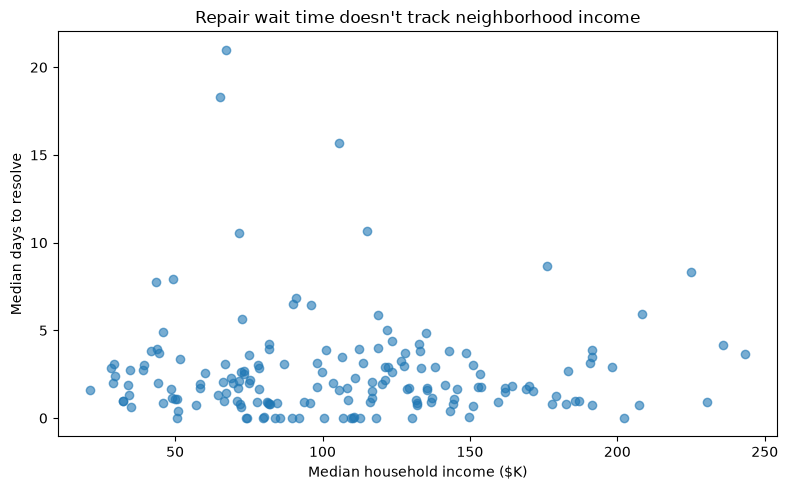

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(tract_stats['median_income'] / 1000, tract_stats['median_days'], alpha=0.6)
ax.set_xlabel('Median household income ($K)')
ax.set_ylabel('Median days to resolve')
ax.set_title(f"Repair wait time doesn't track neighborhood income")
plt.tight_layout()
plt.savefig('income_vs_wait.png', dpi=200)
plt.show()

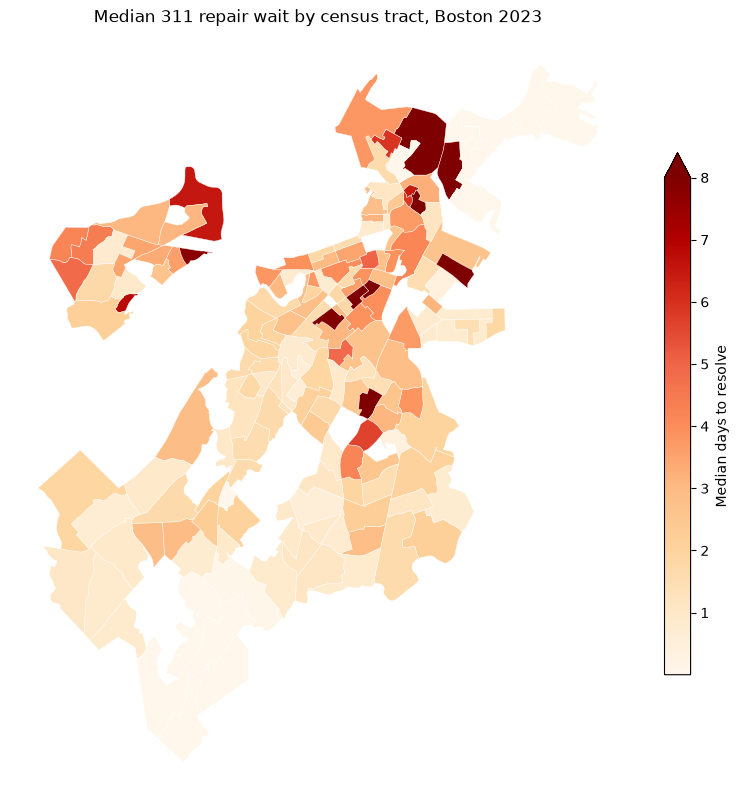

In [15]:
boston = tracts.merge(tract_stats, on='GEOID', how='inner')

fig, ax = plt.subplots(figsize=(8, 9))
boston.plot(column='median_days', cmap='OrRd', legend=True, vmax=8,
            legend_kwds={'label': 'Median days to resolve', 'shrink': 0.6},
            edgecolor='white', linewidth=0.3, ax=ax)
ax.set_title('Median 311 repair wait by census tract, Boston 2023')
ax.axis('off')
plt.tight_layout()
plt.savefig('wait_map.png', dpi=200)
plt.show()

Findings: Across [10,419] resolved pothole, streetlight, and sidewalk requests in 170 Boston census tracts (2023), median household income showed no meaningful relationship with repair time (Spearman ρ = −0.02, p = 0.83). Broken out by type, potholes and streetlights showed no significant link, and sidewalk repairs showed a tentative pattern of higher-income tracts waiting longer (ρ = 0.43, p = 0.015, only 32 tracts). Mapping suggests slower service clusters geographically in East Boston and Charlestown rather than by income.

Limitations: Correlation isn’t causation. “Resolved” may not always mean physically fixed. Tracts with fewer than 15 requests were excluded. The analysis covers one year of data.